# PanEcho EchoNet-Dynamic Fine-Tuning

In [1]:
import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

PROJECT_ROOT = next(
    parent for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.datasets.panecho_echonet_dataset import build_panecho_loaders, load_echonet_records
from src.models.echo.panecho import build_panecho_for_finetuning, load_panecho
from src.training.trainer import Trainer, EarlyStopping, seed_everything

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.0+cu130
CUDA available: True


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

seed_everything(SEED)

print("Device:", DEVICE)
print("Seed:", SEED)

Device: cuda
Seed: 42


In [3]:
MANIFEST_PATH = PROJECT_ROOT / "data" / "processed" / "echo" / "echonet" / "echonet_manifest.csv"
PRETRAINED_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho.pt"
OUTPUT_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho" / "panecho_echonet_finetuned.pt"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "echo" / "panecho"

OUTPUT_CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f"Missing EchoNet manifest: {MANIFEST_PATH}")
if not PRETRAINED_CHECKPOINT.exists():
    raise FileNotFoundError(f"Missing pretrained PanEcho weights: {PRETRAINED_CHECKPOINT}")

print("Manifest:", MANIFEST_PATH)
print("Pretrained PanEcho:", PRETRAINED_CHECKPOINT)
print("Fine-tuned output:", OUTPUT_CHECKPOINT)

Manifest: d:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\processed\echo\echonet\echonet_manifest.csv
Pretrained PanEcho: d:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\echo\panecho.pt
Fine-tuned output: d:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\echo\panecho\panecho_echonet_finetuned.pt


In [4]:
records = load_echonet_records(
    manifest=MANIFEST_PATH,
    project_root=PROJECT_ROOT,
)

print(records[["EF", "EDV", "ESV", "split"]].groupby("split").agg(["count", "mean", "std"]))

         EF                         EDV            ESV         
      count       mean        std count mean std count mean std
split                                                          
test    182  56.752408  12.044741     0  NaN NaN     0  NaN NaN
train  1144  56.292427  11.931044     0  NaN NaN     0  NaN NaN
val     204  55.816417  13.328393     0  NaN NaN     0  NaN NaN


In [5]:
loaders = build_panecho_loaders(
    manifest=MANIFEST_PATH,
    project_root=PROJECT_ROOT,
    batch_size=4,
    seed=SEED,
    eval_num_clips=1,
    num_workers=2,
    augment=True,
)

print({split: len(loader.dataset) for split, loader in loaders.items()})

{'train': 1144, 'val': 204, 'test': 182}


In [6]:
class EchoNetMaskedMSELoss(nn.Module):
    def __init__(self, variances):
        super().__init__()
        self.variances = variances

    def forward(self, outputs, batch):
        total = None
        parts = {}
        target_columns = {"EF": "ef", "LVEDV": "edv", "LVESV": "esv"}
        for head, variance in self.variances.items():
            predicted = outputs[head].float().reshape(-1)
            target = batch[target_columns[head]].float().to(predicted.device).reshape(-1)
            mask = torch.isfinite(target)
            if not mask.any():
                continue
            mse = torch.mean((predicted[mask] - target[mask]) ** 2)
            parts[f"mse_{head}"] = mse.detach()
            total = mse / variance if total is None else total + mse / variance
        if total is None:
            raise ValueError("Batch has no finite EchoNet targets.")
        return total, parts

train_records = records[records["split"] == "train"]
targets = ["EF", "LVEDV", "LVESV"]
columns = {"EF": "EF", "LVEDV": "EDV", "LVESV": "ESV"}
variances = {}

for head in targets:
    values = train_records[columns[head]].to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    variance = float(values.var()) if len(values) >= 2 else 0.0
    if variance >= 1e-6:
        variances[head] = variance

if "EF" not in variances:
    raise ValueError("EF training labels are required.")

print("Fine-tuning heads:", list(variances))

Fine-tuning heads: ['EF']


In [7]:
model = build_panecho_for_finetuning(
    PRETRAINED_CHECKPOINT,
    tasks=list(variances),
    fc_dropout=0.0,
)

# Warm-start guarantee: this loads ConvNeXt, Transformer, and matching EF/EDV/ESV heads.
# No pretrained=False or Imagenet-only scratch initialization is used.
head_params = [p for n, p in model.named_parameters() if not n.startswith("encoder.")]
backbone_params = [p for n, p in model.named_parameters() if n.startswith("encoder.") and not n.endswith("time_encoder.pe")]

optimizer = torch.optim.AdamW(
    [
        {"params": head_params, "lr": 1e-4},
        {"params": backbone_params, "lr": 1e-5},
    ],
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)

trainer = Trainer(
    model=model,
    optimizer=optimizer,
    loss_fn=EchoNetMaskedMSELoss(variances),
    device=DEVICE,
    scheduler=scheduler,
    checkpoint_dir=ARTIFACT_DIR / "checkpoints",
    grad_clip_norm=1.0,
)

print("Warm-started PanEcho task heads:", model.task_names)

Warm-started PanEcho task heads: ['EF']


In [8]:
EPOCHS = 30

history = trainer.fit(
    loaders["train"],
    loaders.get("val"),
    epochs=EPOCHS,
    early_stopping=EarlyStopping(patience=10, mode="min"),
    monitor="loss",
    save_name="panecho_echonet_best.pt",
)

epoch=001 train_loss=0.39152 train_mse_EF=55.68413 val_loss=0.51035 val_mse_EF=72.58472
epoch=002 train_loss=0.35019 train_mse_EF=49.80624 val_loss=0.45175 val_mse_EF=64.25048
epoch=003 train_loss=0.29252 train_mse_EF=41.60358 val_loss=0.44293 val_mse_EF=62.99561
epoch=004 train_loss=0.24788 train_mse_EF=35.25535 val_loss=0.45895 val_mse_EF=65.27487
epoch=005 train_loss=0.22764 train_mse_EF=32.37637 val_loss=0.43508 val_mse_EF=61.87938
epoch=006 train_loss=0.19413 train_mse_EF=27.60956 val_loss=0.43856 val_mse_EF=62.37387
epoch=007 train_loss=0.17396 train_mse_EF=24.74202 val_loss=0.43862 val_mse_EF=62.38288
epoch=008 train_loss=0.16793 train_mse_EF=23.88427 val_loss=0.45535 val_mse_EF=64.76287
epoch=009 train_loss=0.15970 train_mse_EF=22.71326 val_loss=0.46441 val_mse_EF=66.05116
epoch=010 train_loss=0.14545 train_mse_EF=20.68611 val_loss=0.48163 val_mse_EF=68.49962
epoch=011 train_loss=0.14221 train_mse_EF=20.22616 val_loss=0.45811 val_mse_EF=65.15533
epoch=012 train_loss=0.12232 tra

In [9]:
history_path = ARTIFACT_DIR / "history.json"
history_path.write_text(json.dumps(history, indent=2), encoding="utf-8")

stage_checkpoint = ARTIFACT_DIR / "checkpoints" / "panecho_echonet_best.pt"
if not stage_checkpoint.exists():
    raise FileNotFoundError(stage_checkpoint)

payload = torch.load(stage_checkpoint, map_location="cpu", weights_only=True)
torch.save(
    {
        "model_state_dict": payload["model_state_dict"],
        "panecho_tasks": list(variances),
        "clip_len": 16,
        "source": "PanEcho pretrained checkpoint fine-tuned on EchoNet-Dynamic",
        "pretrained_checkpoint": str(PRETRAINED_CHECKPOINT),
        "epoch": payload["epoch"],
        "val_metrics": payload["metrics"],
    },
    OUTPUT_CHECKPOINT,
)

print("Fine-tuned checkpoint:", OUTPUT_CHECKPOINT)
print("History:", history_path)

Fine-tuned checkpoint: d:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\echo\panecho\panecho_echonet_finetuned.pt
History: d:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\artifacts\echo\panecho\history.json


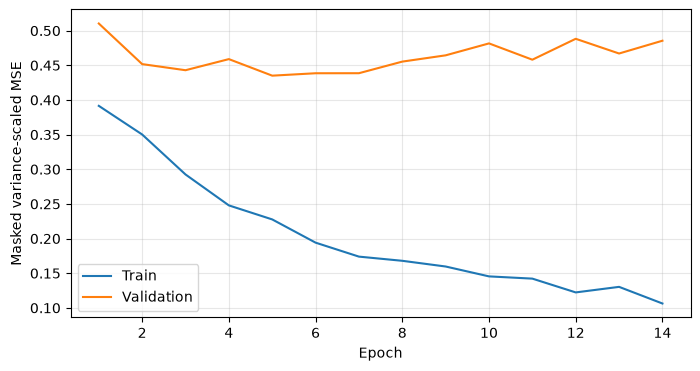

In [10]:
if history:
    train_loss = [row["train_loss"] for row in history]
    val_loss = [row["val_loss"] for row in history if "val_loss" in row]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, len(train_loss) + 1), train_loss, label="Train")
    if val_loss:
        ax.plot(range(1, len(val_loss) + 1), val_loss, label="Validation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Masked variance-scaled MSE")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()